# IP forward modelling time vs frequency domain

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

In [2]:
# make the system setup. 
# these components are in the experiment module.

from anemone.experiment import *

tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([
    ButterworthFilter(2.4e5, 1),
    ButterworthFilter(6.2e5, 1),
    ButterworthFilter(4.5e5, 2)
])

In [9]:
# make the forward operators
# these are in the forwards module

from anemone.forwards import *

times = torch.logspace(-5, -3, 32)
fwrTD = IPForward(tx, rx, times, filterfunc=recfilter)

# frqs = (torch.arange(32)+1)*2e3
frqs = torch.logspace(3, 6, 51)
fwrFD = IPForwardFD(tx, rx, frqs, filterfunc=recfilter)

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:108: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [10]:
rho = torch.tensor([40, 80, 300], dtype=torch.double)
thickness = torch.tensor([20, 30], dtype=torch.double)
tau = torch.ones(3, dtype=torch.double)*1e-4
c = torch.ones(3, dtype=torch.double)*0.6
c[1] = 0.9
m = torch.tensor([0.2, 0.5, 0.9], dtype=torch.double)

dbdt = fwrTD(rho, tau,  m, c, thickness).real
Bfrq = fwrFD(rho, tau,  m, c, thickness)

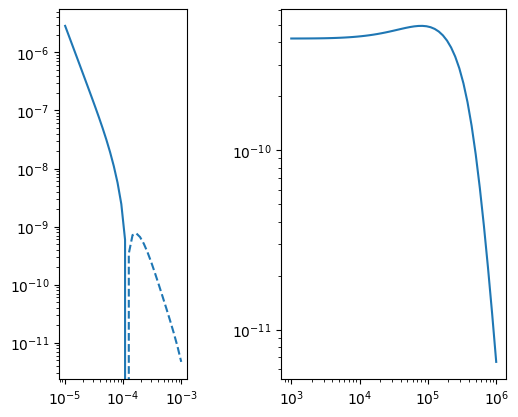

In [11]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(times, dbdt, 'C0')
axs[0].loglog(times,-dbdt, 'C0--')
axs[0].set_aspect('equal')
axs[1].loglog(frqs, torch.abs(Bfrq), 'C0')

In [12]:
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

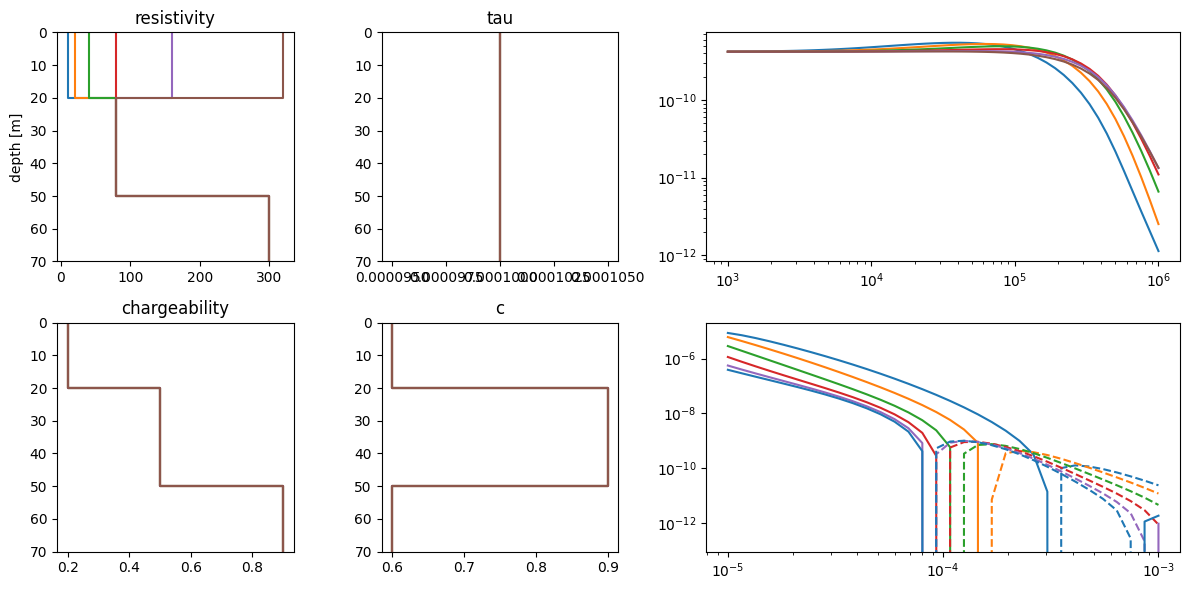

In [13]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()
for i,r2 in enumerate([10, 20, 40, 80, 160, 320]):
    cmod = FewLayerColeCole([r2, 80, 300], [1e-4, 1e-4, 1e-4], [0.2, 0.5, 0.9], [0.6, 0.9, 0.6], [20, 30])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)
plt.tight_layout()

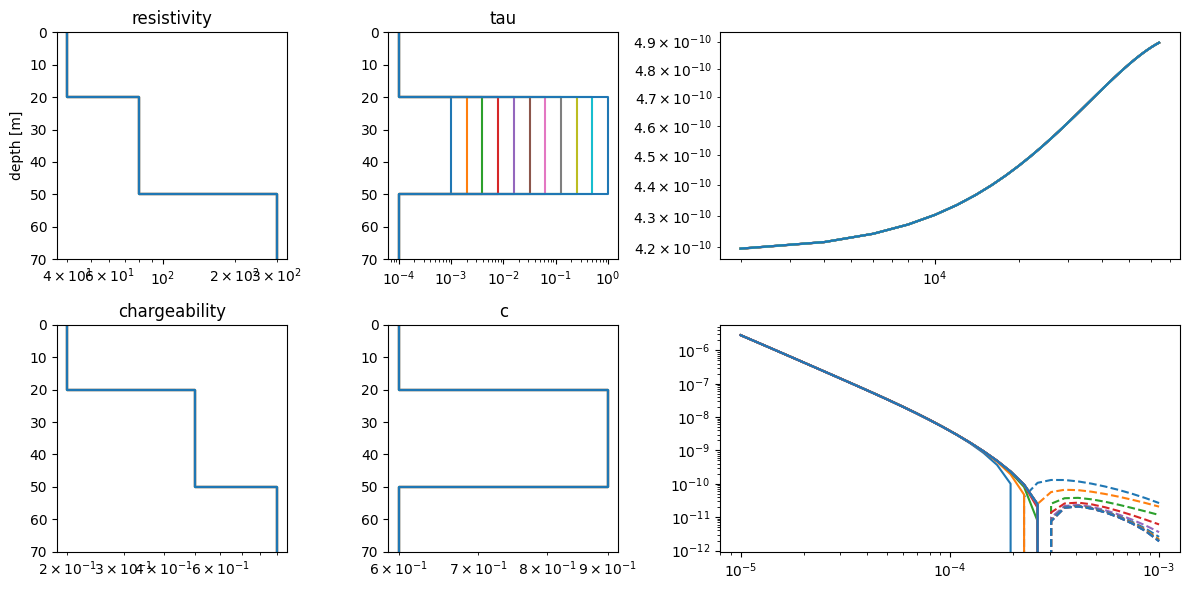

In [21]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()

for i,tau2 in enumerate(np.logspace(-3, 0, 11)):
    cmod = FewLayerColeCole([40, 80, 300], [1e-4, tau2, 1e-4], [0.2, 0.5, 0.9], [0.6, 0.9, 0.6], [20, 30])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)
        ax.set_xscale('log')
plt.tight_layout()

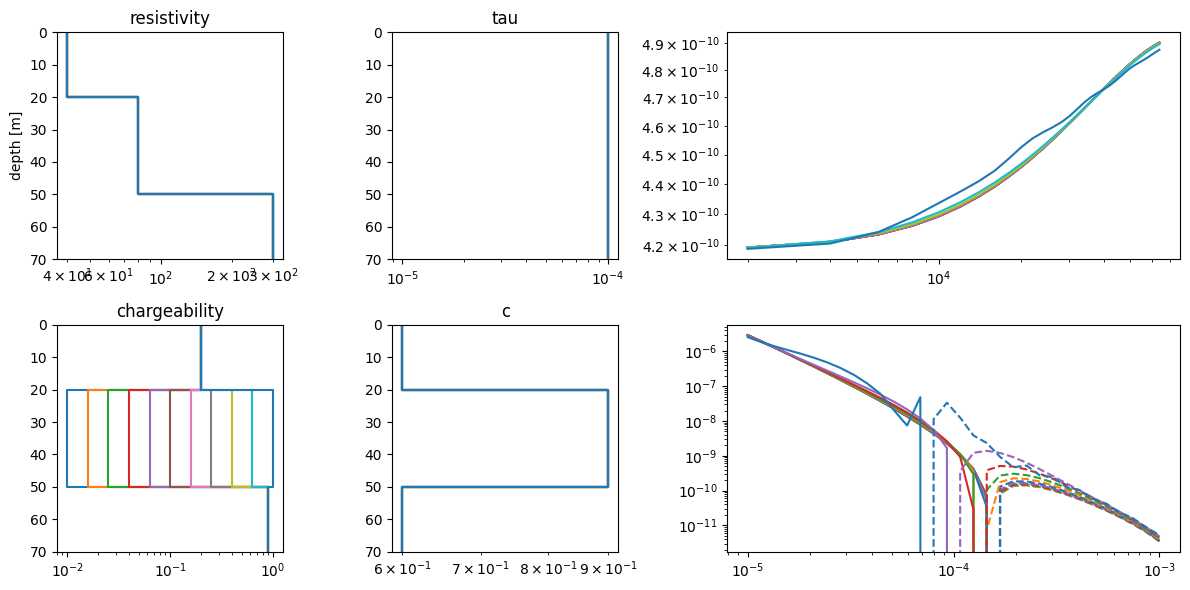

In [22]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()

for i,m2 in enumerate(np.logspace(-2, 0, 11)):
    cmod = FewLayerColeCole([40, 80, 300], [1e-4, 1e-4, 1e-4], [0.2, m2, 0.9], [0.6, 0.9, 0.6], [20, 30])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)

        ax.set_xscale('log')
plt.tight_layout()

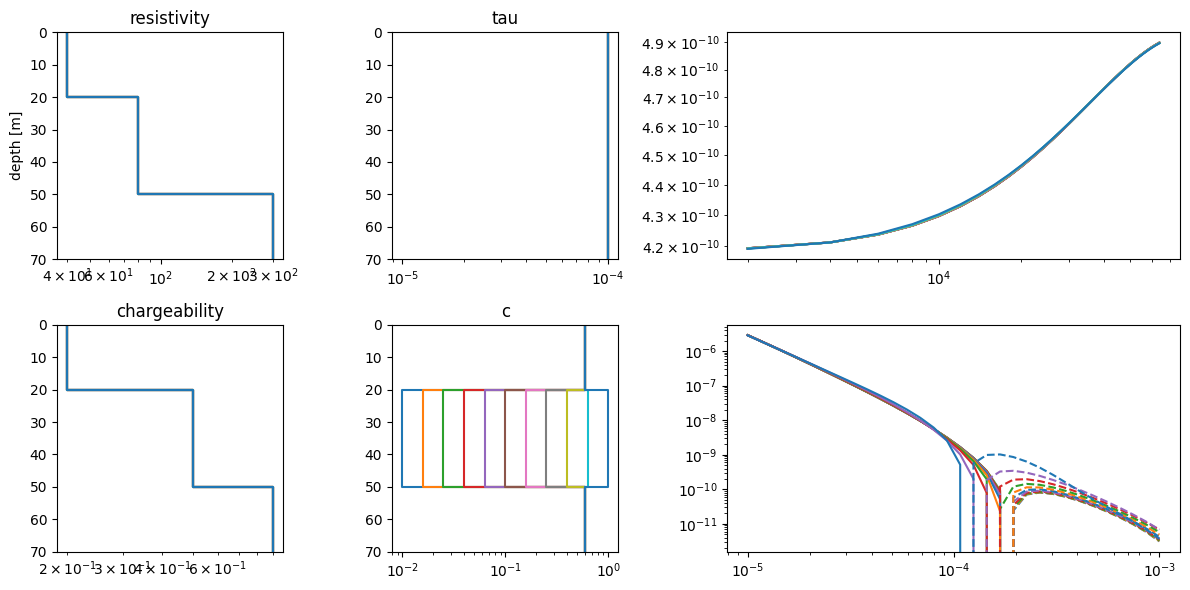

In [23]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()

for i,c2 in enumerate(np.logspace(-2, 0, 11)):
    cmod = FewLayerColeCole([40, 80, 300], [1e-4, 1e-4, 1e-4], [0.2, 0.5, 0.9], [0.6, c2, 0.6], [20, 30])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)

        ax.set_xscale('log')
plt.tight_layout()

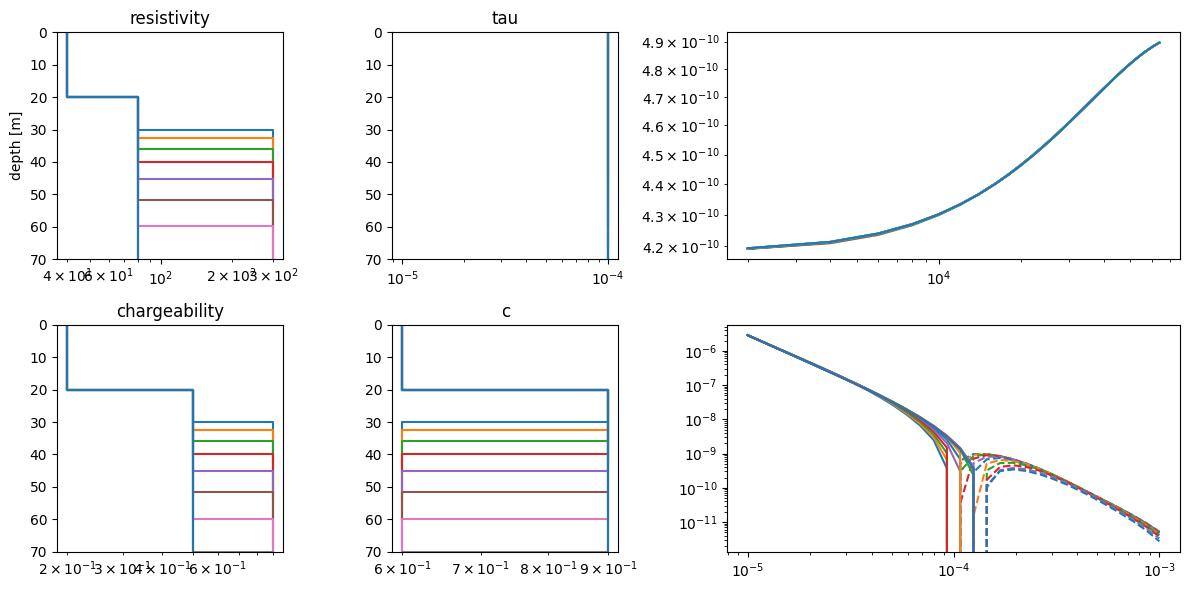

In [24]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()

for i,thk2 in enumerate(np.logspace(1, 2, 11)):
    cmod = FewLayerColeCole([40, 80, 300], [1e-4, 1e-4, 1e-4], [0.2, 0.5, 0.9], [0.6, 0.9, 0.6], [20, thk2])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)

        ax.set_xscale('log')
plt.tight_layout()